# The Part-Time Penalty — Notebook 01: Data Cleaning & Baseline EDA
**Research question:** Do part-time postings advertise fewer essential benefits than full-time postings, even at similar hourly wages?

**Important:** Not listing a benefit does **not** prove an employer does not offer it. This notebook measures **advertised benefit disclosure**. Do not interpret these descriptive comparisons as causal effects.

**Run cells from top to bottom.** Use the **full** `compressedindeedjobscsv.zip`, not the sample or Glassdoor ZIP.

## 1. Mount Drive and find the ZIP
Upload `compressedindeedjobscsv.zip` to `My Drive/The Part-Time Penalty/Raw Data/` first.

In [1]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import zipfile, json, re, ast, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('/content/drive/MyDrive/The Part-Time Penalty')
RAW = ROOT / 'Raw Data'
CLEAN = ROOT / 'Cleaned Data'
FIGS = ROOT / 'Visualizations'
for folder in [RAW, CLEAN, FIGS]:
    folder.mkdir(parents=True, exist_ok=True)
ZIP_PATH = RAW / 'compressedindeedjobscsv.zip'
assert ZIP_PATH.exists(), f'ZIP not found: {ZIP_PATH}. Check the folder name and upload location.'
with zipfile.ZipFile(ZIP_PATH) as z:
    csv_names = [x for x in z.namelist() if x.lower().endswith('.csv')]
print('CSV files inside ZIP:', csv_names)
assert len(csv_names) == 1, 'Please check the ZIP contents; expected one CSV.'
CSV_NAME = csv_names[0]


Mounted at /content/drive
CSV files inside ZIP: ['indeed_job_listings-001 (2).csv']


## 2. Read the large CSV in chunks
The source CSV is over 2 GB uncompressed. We load only eight useful columns, in chunks, to avoid Colab running out of RAM.

In [2]:
COLS = ['jobid','job_title','job_type','salary_formatted','benefits',
        'location','company_name','date_posted_parsed']
chunks = []
rows_seen = 0
with zipfile.ZipFile(ZIP_PATH) as z:
    with z.open(CSV_NAME) as f:
        for i, chunk in enumerate(pd.read_csv(
            f, usecols=COLS, chunksize=15000, dtype='string',
            encoding='utf-8-sig', on_bad_lines='warn', low_memory=False
        )):
            rows_seen += len(chunk)
            chunks.append(chunk)
            if (i + 1) % 5 == 0:
                print(f'Read {rows_seen:,} rows')
df = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()
print('Rows loaded:', len(df))
print('Columns:', df.columns.tolist())
display(df.head(3))


Read 75,000 rows
Read 140,816 rows
Rows loaded: 140816
Columns: ['jobid', 'company_name', 'date_posted_parsed', 'job_title', 'benefits', 'job_type', 'location', 'salary_formatted']


,jobid,company_name,date_posted_parsed,job_title,benefits,job_type,location,salary_formatted
0,8a7ded2477edeaf1,"Perrygo Consulting Group, LLC",2026-03-02T20:16:41.308Z,Operations Research Analyst - Journeyman - Sec...,"[""AD&D insurance"",""401(k)"",""Health insurance"",...",Contract,"San Diego, CA",<NA>
1,e889a0d1f6cb1e0d,Northwestern Mutual,2026-07-10T00:42:05.890Z,Financial Advisor,"[""Health insurance"",""Vision insurance"",""Dental...",Full-time,"18575 Jamboree Road, Irvine, CA 92612","$61,000 - $250,000 a year"
2,45a72242e79b4923,East West Bank,2026-02-28T14:03:38.831Z,Business Relationship Manager,"[""Opportunities for advancement""]",Full-time,"900 Webster St, Oakland, CA 94607","$71,000 - $140,000 a year"


## 3. Audit raw data quality
Record the results for the Methods section of your presentation.

In [3]:
print('Total rows:', f'{len(df):,}')
print('Duplicate nonempty job IDs:', int(df.loc[df.jobid.notna() & df.jobid.str.strip().ne(''), 'jobid'].duplicated().sum()))
missing = pd.DataFrame({'missing_n': df.isna().sum(), 'missing_pct': (df.isna().mean()*100).round(2)})
display(missing.sort_values('missing_pct', ascending=False))
print('Top job_type values:')
display(df['job_type'].fillna('[missing]').value_counts().head(25).to_frame('postings'))
print('Sample salary formats:')
display(df['salary_formatted'].dropna().drop_duplicates().sample(min(20, df['salary_formatted'].nunique()), random_state=42).to_frame())
print('Sample benefit formats:')
display(df['benefits'].dropna().drop_duplicates().head(8).to_frame())


Total rows: 140,816
Duplicate nonempty job IDs: 0


,missing_n,missing_pct
job_type,30395,21.58
salary_formatted,20392,14.48
benefits,6864,4.87
jobid,0,0.00
job_title,0,0.00
date_posted_parsed,0,0.00
company_name,0,0.00
location,0,0.00


Top job_type values:


,postings
job_type,
Full-time,76395
[missing],30395
Part-time,17542
"Part-time, Full-time",6617
Contract,2214
Per diem,870
"Full-time, Contract",777
"Part-time, Full-time, Contract",663
Internship,500


Sample salary formats:


,salary_formatted
1410,"$180,000 - $270,000 a year"
10878,$20.77 - $25.96 an hour
125053,"$176,000 - $276,000 por año"
36423,"$98,819.53 - $117,844.00 a year"
98565,"$142,750 - $178,500 a year"
132595,$15 - $45 an hour
28720,"$93,750 - $125,000 a year"
121351,"$46,612.80 - $68,993.60 por año"
139572,"$181,272 - $182,000 a year"
133987,"$45,000.00 - $62,754.38 por año"


Sample benefit formats:


,benefits
0,"[""AD&D insurance"",""401(k)"",""Health insurance"",..."
1,"[""Health insurance"",""Vision insurance"",""Dental..."
2,"[""Opportunities for advancement""]"
3,"[""401(k)"",""Health insurance"",""Retirement plan""..."
4,"[""Malpractice insurance"",""Loan repayment progr..."
5,[]
6,"[""401(k)"",""Health insurance"",""Paid time off"",""..."
8,"[""Health insurance"",""Paid time off""]"


## 4. Deduplicate and classify employment type
Use only **unambiguous** Full-time-only and Part-time-only postings for the main comparison. Mixed labels are kept in the data but excluded from the baseline chart.

In [4]:
# Deduplicate valid job IDs, but do NOT collapse all rows with missing IDs into one.
df['jobid'] = df['jobid'].str.strip()
valid_id = df['jobid'].notna() & df['jobid'].ne('')
df = pd.concat([df.loc[valid_id].drop_duplicates(subset='jobid'),
                df.loc[~valid_id].drop_duplicates(subset=['company_name','job_title','location','salary_formatted','job_type'])],
               ignore_index=True)

def classify_type(value):
    if pd.isna(value): return 'Unknown/Other'
    s = str(value).lower()
    full = bool(re.search(r'full[ -]?time', s))
    part = bool(re.search(r'part[ -]?time', s))
    if full and not part: return 'Full-time'
    if part and not full: return 'Part-time'
    if full and part: return 'Mixed'
    return 'Unknown/Other'

df['employment_type'] = df['job_type'].map(classify_type)
print('Rows after deduplication:', f'{len(df):,}')
display(df['employment_type'].value_counts().to_frame('postings'))


Rows after deduplication: 140,816


,postings
employment_type,
Full-time,78503
Unknown/Other,35996
Part-time,18490
Mixed,7827


## 5. Parse salaries into comparable hourly rates
Assumptions: 40 hours/week × 52 weeks/year; 8 hours/day; 40 hours/week; 4.333 weeks/month. These conversions are approximations, not actual scheduled hours. We exclude `From`, `Up to`, mixed units, and unclear pay from the **same-wage** analysis unless they can be interpreted safely.

In [5]:
def parse_hourly_salary(value):
    if pd.isna(value) or not str(value).strip(): return (np.nan, np.nan, 'missing')
    s = str(value).lower().replace(',', '')
    units = re.findall(r'(?:an?\s+)?(hour|year|month|week|day)', s)
    units = list(dict.fromkeys(units))
    if len(units) != 1: return (np.nan, np.nan, 'unclear_unit')
    unit = units[0]
    amounts = [float(x) for x in re.findall(r'\$\s*(\d+(?:\.\d+)?)', s)]
    if not amounts or len(amounts) > 2: return (np.nan, np.nan, 'unclear_amount')
    if 'from ' in s or 'up to' in s or 'starting at' in s:
        return (np.nan, np.nan, 'one_sided_range')
    if len(amounts) == 2 and not re.search(r'to|[-–—]', s):
        return (np.nan, np.nan, 'unclear_range')
    lo, hi = min(amounts), max(amounts)
    factors = {'hour':1, 'year':1/2080, 'month':12/2080,
               'week':1/40, 'day':1/8}
    lo, hi = lo*factors[unit], hi*factors[unit]
    if lo < 5 or hi > 500: return (np.nan, np.nan, 'implausible')
    return (lo, hi, 'parsed')

parsed = df['salary_formatted'].map(parse_hourly_salary)
df[['hourly_min','hourly_max','salary_parse_status']] = pd.DataFrame(parsed.tolist(), index=df.index)
df['hourly_midpoint'] = (df['hourly_min'] + df['hourly_max'])/2
print('Salary parsing outcomes:')
display(df['salary_parse_status'].value_counts().to_frame('postings'))
print('Examples of parsed wages:')
display(df.loc[df['hourly_midpoint'].notna(), ['salary_formatted','hourly_min','hourly_max','hourly_midpoint']].head(12))


Salary parsing outcomes:


,postings
salary_parse_status,
unclear_unit,120424
missing,20392


Examples of parsed wages:


,salary_formatted,hourly_min,hourly_max,hourly_midpoint


## 6. Parse the structured benefits list
The raw field usually contains a JSON list. Keep **no benefits field** distinct from **a list that does not mention a particular benefit**.

In [6]:
def parse_benefits(value):
    if pd.isna(value) or not str(value).strip(): return None
    s = str(value).strip()
    try:
        result = json.loads(s)
    except (ValueError, TypeError):
        try: result = ast.literal_eval(s)
        except (ValueError, SyntaxError): return None
    if not isinstance(result, list): return None
    return [str(x).strip().lower() for x in result if str(x).strip()]

df['benefits_parsed'] = df['benefits'].map(parse_benefits)
df['benefits_disclosed'] = df['benefits_parsed'].map(lambda x: isinstance(x,list) and len(x)>0)

def has_benefit(items, patterns):
    if not isinstance(items,list): return False
    return any(any(re.search(p, item) for p in patterns) for item in items)

BENEFIT_PATTERNS = {
    'health_insurance': [r'health insurance', r'medical insurance', r'medical coverage'],
    'paid_time_off': [r'paid time off', r'paid vacation', r'vacation pay', r'paid sick', r'unlimited paid time off'],
    'retirement': [r'401\s*\(?k\)?', r'403\s*\(?b\)?', r'retirement plan', r'pension plan'],
    'dental_insurance': [r'dental insurance', r'dental coverage'],
    'flexible_schedule': [r'flexible schedule', r'flexible hours', r'flexible work schedule']
}
for col, patterns in BENEFIT_PATTERNS.items():
    df[col] = df['benefits_parsed'].map(lambda x: has_benefit(x, patterns))

print('Nonempty structured benefit lists:', int(df['benefits_disclosed'].sum()))
print('Missing or unparseable/empty benefit lists:', int((~df['benefits_disclosed']).sum()))
for col in BENEFIT_PATTERNS:
    print(f'{col}: {df[col].sum():,} explicit mentions')


Nonempty structured benefit lists: 89299
Missing or unparseable/empty benefit lists: 51517
health_insurance: 66,957 explicit mentions
paid_time_off: 48,233 explicit mentions
retirement: 60,862 explicit mentions
dental_insurance: 60,481 explicit mentions
flexible_schedule: 13,734 explicit mentions


## 7. Baseline EDA: Full-time vs part-time
The denominator is **all unambiguous postings**, including those with no listed benefits. These are disclosure rates, not verified access rates.

Number of postings in each group:


,postings
employment_type,
Full-time,78503
Part-time,18490


,health_insurance,paid_time_off,retirement,dental_insurance,flexible_schedule
employment_type,,,,,
Full-time,55.71,41.28,50.24,50.46,7.10
Part-time,29.84,22.85,31.82,29.15,20.91


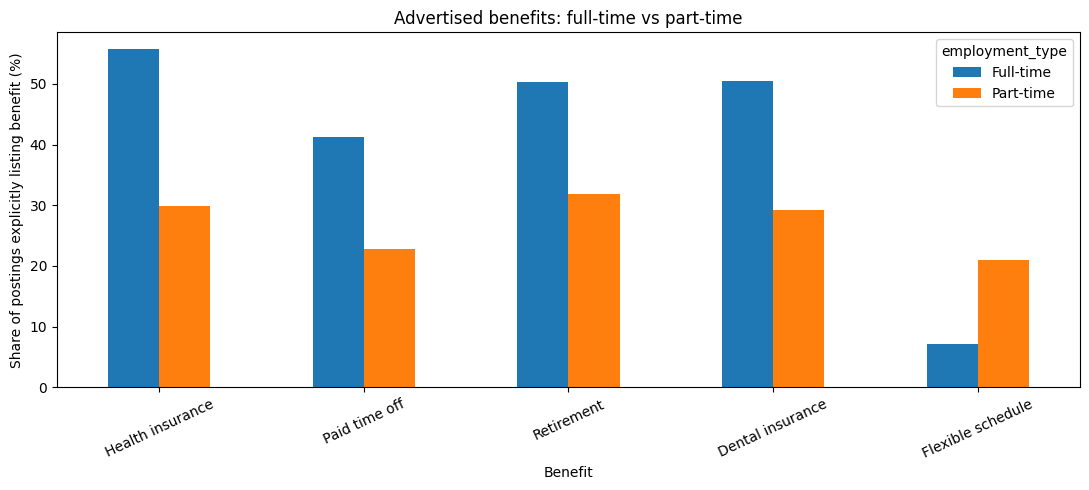

Full-time minus part-time disclosure gap (percentage points):


,gap_pp
health_insurance,25.87
dental_insurance,21.30
paid_time_off,18.43
retirement,18.43
flexible_schedule,-13.81


In [7]:
compare = df[df['employment_type'].isin(['Full-time','Part-time'])].copy()
benefit_cols = list(BENEFIT_PATTERNS)
counts = compare['employment_type'].value_counts().reindex(['Full-time','Part-time'])
print('Number of postings in each group:')
display(counts.to_frame('postings'))
rates = compare.groupby('employment_type')[benefit_cols].mean().mul(100).reindex(['Full-time','Part-time'])
display(rates.round(2))

ax = rates.T.rename(index={
    'health_insurance':'Health insurance', 'paid_time_off':'Paid time off',
    'retirement':'Retirement', 'dental_insurance':'Dental insurance',
    'flexible_schedule':'Flexible schedule'
}).plot(kind='bar', figsize=(11,5))
ax.set_ylabel('Share of postings explicitly listing benefit (%)')
ax.set_xlabel('Benefit')
ax.set_title('Advertised benefits: full-time vs part-time')
ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig(FIGS/'01_benefit_disclosure_by_employment_type.png', dpi=180, bbox_inches='tight')
plt.show()

# Also calculate the gaps, in percentage points.
gaps = (rates.loc['Full-time'] - rates.loc['Part-time']).sort_values(ascending=False)
print('Full-time minus part-time disclosure gap (percentage points):')
display(gaps.round(2).to_frame('gap_pp'))


## 8. Same-wage comparison (first look)
Use only confidently parsed wages. Wage bands are descriptive; **occupation-adjusted comparisons come in Notebook 02**. Print group counts to avoid interpreting tiny subgroups.

In [10]:
bins = [0, 15, 20, 25, 30, 40, 60, np.inf]
labels = ['<$15', '$15–20', '$20–25', '$25–30', '$30–40', '$40–60', '$60+']
compare['wage_band'] = pd.cut(compare['hourly_midpoint'], bins=bins, labels=labels, right=False)
print('Jobs with valid hourly wage:', compare['hourly_midpoint'].notna().sum())
print('Wage band counts:')
display(compare['wage_band'].value_counts(dropna=False))

for benefit in ['health_insurance', 'paid_time_off', 'retirement']:
    summary = (compare.groupby(['wage_band', 'employment_type'], observed=True)
               .agg(postings=('jobid', 'size'), rate=(benefit, 'mean'))
               .reset_index())
    summary['rate'] = pd.to_numeric(summary['rate'], errors='coerce') * 100
    print('\nBenefit:', benefit)
    display(summary)
    plot = summary.pivot(index='wage_band', columns='employment_type', values='rate')
    plot = plot.reindex(labels).reindex(columns=['Full-time', 'Part-time'])
    plot = plot.apply(pd.to_numeric, errors='coerce')
    if plot.notna().sum().sum() == 0:
        print('No valid numeric rates to graph. Check the salary parsing outcomes above.')
        continue
    ax = plot.plot(kind='bar', figsize=(10, 4))
    ax.set_title(f'{benefit.replace("_", " ").title()} disclosure within wage bands')
    ax.set_ylabel('Postings explicitly listing benefit (%)')
    ax.set_xlabel('Approximate hourly wage band')
    ax.tick_params(axis='x', rotation=25)
    plt.tight_layout()
    plt.savefig(FIGS / f'02_{benefit}_by_wage_band.png', dpi=180, bbox_inches='tight')
    plt.show()


Jobs with valid hourly wage: 0
Wage band counts:


,count
wage_band,
NaN,96993
<$15,0
$20–25,0
$15–20,0
$25–30,0
$30–40,0
$40–60,0
$60+,0



Benefit: health_insurance


,wage_band,employment_type,postings,rate


No valid numeric rates to graph. Check the salary parsing outcomes above.

Benefit: paid_time_off


,wage_band,employment_type,postings,rate


No valid numeric rates to graph. Check the salary parsing outcomes above.

Benefit: retirement


,wage_band,employment_type,postings,rate


No valid numeric rates to graph. Check the salary parsing outcomes above.


## 9. Sensitivity check: postings with a nonempty benefit list only
This is **not** a replacement for the primary analysis. It helps show whether differences are driven by whether employers list any benefits at all.

In [11]:
subset = compare[compare['benefits_disclosed']]
print('Postings with nonempty benefit lists, by employment type:')
display(subset['employment_type'].value_counts().to_frame('postings'))
display((subset.groupby('employment_type')[benefit_cols].mean()*100).round(2))


Postings with nonempty benefit lists, by employment type:


,postings
employment_type,
Full-time,53097
Part-time,11369


,health_insurance,paid_time_off,retirement,dental_insurance,flexible_schedule
employment_type,,,,,
Full-time,82.36,61.04,74.28,74.60,10.5
Part-time,48.53,37.16,51.75,47.41,34.0


## 10. Export cleaned data and audit outputs
Save the results to Drive so the next notebook and Tableau can use them. Do not export raw descriptions; we did not need them for this analysis.

In [12]:
export_cols = COLS + ['employment_type','hourly_min','hourly_max','hourly_midpoint',
                            'salary_parse_status','benefits_disclosed'] + benefit_cols
export = df[export_cols].copy()
output = CLEAN/'indeed_cleaned_part_time_penalty.csv.gz'
export.to_csv(output,index=False,compression='gzip')
rates.to_csv(CLEAN/'baseline_benefit_rates.csv')
missing.to_csv(CLEAN/'raw_missingness.csv')
print('Saved:',output)
print('Saved baseline rates and missingness report to:',CLEAN)
print('Saved figures to:',FIGS)
print('NEXT: Manually inspect 30–50 raw records, then create occupation groups in Notebook 02.')


Saved: /content/drive/MyDrive/The Part-Time Penalty/Cleaned Data/indeed_cleaned_part_time_penalty.csv.gz
Saved baseline rates and missingness report to: /content/drive/MyDrive/The Part-Time Penalty/Cleaned Data
Saved figures to: /content/drive/MyDrive/The Part-Time Penalty/Visualizations
NEXT: Manually inspect 30–50 raw records, then create occupation groups in Notebook 02.
